# 真实水下公开数据：EUVP 配对图像

使用真实水下拍摄的公开 EUVP 数据，不使用水果照片或生成图。比较输入、传统增强结果和数据集配对参考图。

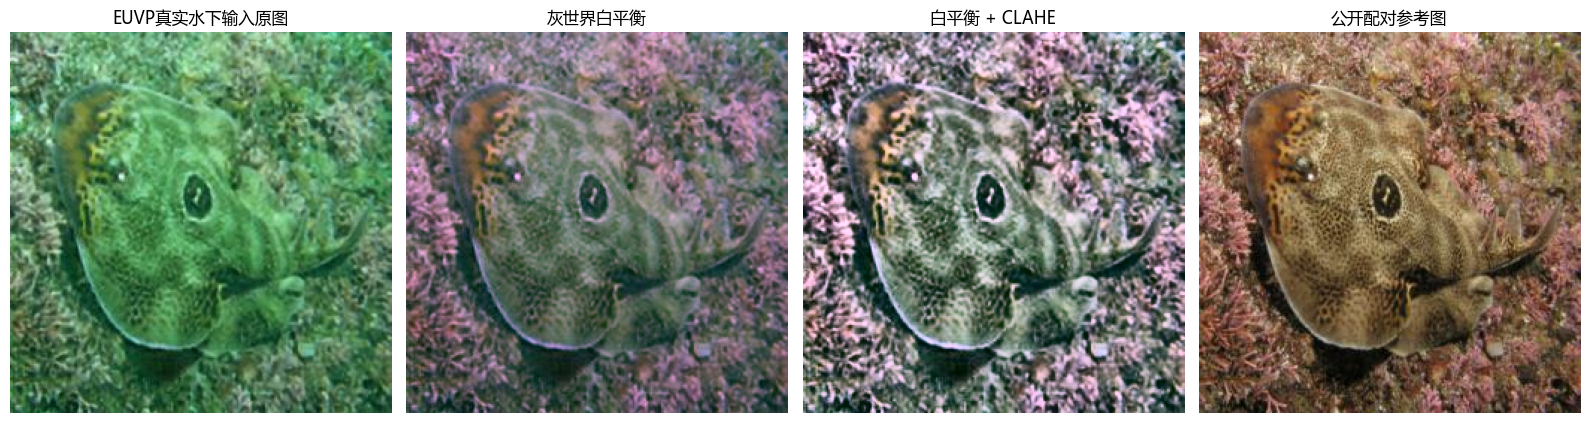

输入/参考尺寸: (256, 256, 3) (256, 256, 3) ；数据来自公开 EUVP 测试集，参考图不等于逐像素物理真值。


In [1]:
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "courses/industrial-vision-lab/data/public/underwater/euvp_test_input_1.jpg").exists())
import sys
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from course_utils import configure_plot_fonts
configure_plot_fonts()
base = ROOT / "courses/industrial-vision-lab/data/public/underwater"
inp = cv2.cvtColor(cv2.imread(str(base / "euvp_test_input_1.jpg")), cv2.COLOR_BGR2RGB)
ref = cv2.cvtColor(cv2.imread(str(base / "euvp_test_reference_1.jpg")), cv2.COLOR_BGR2RGB)
assert inp is not None and ref is not None
means = inp.astype(np.float32).mean(axis=(0,1)); gain = np.clip(means.mean()/np.maximum(means,1), .5, 2.5)
balanced = np.uint8(np.clip(inp.astype(np.float32)*gain, 0, 255))
lab = cv2.cvtColor(balanced, cv2.COLOR_RGB2LAB); l,a,b=cv2.split(lab); l=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(l)
enhanced = cv2.cvtColor(cv2.merge([l,a,b]), cv2.COLOR_LAB2RGB)
fig, axs = plt.subplots(1, 4, figsize=(16, 5));
for ax, im, title in zip(axs,[inp,balanced,enhanced,ref],["EUVP真实水下输入原图","灰世界白平衡","白平衡 + CLAHE","公开配对参考图"]): ax.imshow(im); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
print("输入/参考尺寸:", inp.shape, ref.shape, "；数据来自公开 EUVP 测试集，参考图不等于逐像素物理真值。")